In [1]:
import pandas as pd

df_train = pd.read_csv('/kaggle/input/datasets/luan85/viet-vqa/train_with_critical_noun.csv')
df_test = pd.read_csv('/kaggle/input/datasets/luan85/viet-vqa/test_with_critical_noun.csv', index_col=0)
df_val = pd.read_csv('/kaggle/input/datasets/luan85/viet-vqa/val_with_critical_noun.csv')

df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

vinvl_h5_path = '/kaggle/input/models/khoileee/embedding-vinvl/pytorch/default/1/VinVL.hdf5'   # change if needed

In [2]:
!pip install deep-translator
!pip install sentence-transformers nltk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 1.6 MB/s eta 0:00:00


In [3]:
import nltk

from nltk.stem import WordNetLemmatizer
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download("wordnet")
nltk.download("omw-1.4")

lemmatizer = WordNetLemmatizer()
text_model = SentenceTransformer("all-MiniLM-L6-v2")

[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /usr/share/nltk_data...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (4 outputs left out)

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [4]:
import os
import re
import pickle
import h5py
import numpy as np

from tqdm import tqdm
from deep_translator import GoogleTranslator

In [5]:
translator = GoogleTranslator(source="vi", target="en")

In [6]:
import time
from deep_translator.exceptions import TranslationNotFound

translation_cache = {}

def translate_term(t, max_retries=5):
    t = str(t).strip()

    if t in translation_cache:
        return translation_cache[t]

    for attempt in range(max_retries):
        try:
            result = translator.translate(t)

            if result and str(result).strip():
                result = str(result).strip()
                translation_cache[t] = result
                return result

        except TranslationNotFound as e:
            print(
                f"TranslationNotFound for {t!r} "
                f"(attempt {attempt + 1}/{max_retries})"
            )

        except Exception as e:
            print(
                f"Translation error for {t!r}: "
                f"{type(e).__name__}: {e}"
            )

        if attempt < max_retries - 1:
            time.sleep(1.5 * (attempt + 1))

    print(f"Giving up translating {t!r}")
    translation_cache[t] = None
    return None

def translate_terms(terms):
    translated = []

    for t in terms:
        result = translate_term(t)

        if result is not None:
            translated.append(result)
        else:
            print("ERROR TRANSLATING")

    return translated

In [7]:
def get_critical_noun(row):
    critical_noun = row.get("critical_noun", None)

    if critical_noun is None or pd.isna(critical_noun):
        return []

    critical_noun = str(critical_noun).strip()

    if critical_noun == "":
        return []

    return [critical_noun]

In [8]:
CANONICAL_MAP = {
    "people": "person",
    "man": "person",
    "woman": "person",
    "boy": "person",
    "girl": "person",
    "men": "person",
    "women": "person",
    "child": "person",
    "children": "person",

    "shirt": "shirt",
    "jersey": "shirt",
    "tshirt": "shirt",
    "t-shirt": "shirt",

    "bike": "bicycle",
    "bicycle": "bicycle",

    "tv": "television",
    "monitor": "television",
    "television": "television",

    "sofa": "couch",
    "couch": "couch",

    "cellphone": "phone",
    "phone": "phone",
    "mobile": "phone",

    "automobile": "car",
    "car": "car",
}

In [9]:
def normalize_text(s):
    s = str(s).lower().strip()
    s = re.sub(r"[_\-/]", " ", s)
    s = re.sub(r"[^a-z0-9\s]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

def lemmatize_phrase(s):
    tokens = normalize_text(s).split()
    tokens = [lemmatizer.lemmatize(tok) for tok in tokens]
    return " ".join(tokens)

def canonicalize_phrase(s):
    s = lemmatize_phrase(s)
    tokens = s.split()
    mapped = [CANONICAL_MAP.get(tok, tok) for tok in tokens]
    return " ".join(mapped)

In [10]:
def lexical_similarity(a, b):
    a = canonicalize_phrase(a)
    b = canonicalize_phrase(b)

    if a == b:
        return 1.0

    a_tokens = set(a.split())
    b_tokens = set(b.split())

    if not a_tokens or not b_tokens:
        return 0.0

    inter = len(a_tokens & b_tokens)
    union = len(a_tokens | b_tokens)
    jaccard = inter / union if union > 0 else 0.0

    substring_bonus = 0.0
    if a in b or b in a:
        substring_bonus = 0.25

    return min(1.0, jaccard + substring_bonus)

In [11]:
def embedding_similarity(a, b):
    a = canonicalize_phrase(a)
    b = canonicalize_phrase(b)

    emb = text_model.encode([a, b], normalize_embeddings=True)
    sim = float(np.dot(emb[0], emb[1]))   # cosine because normalized
    return max(0.0, min(1.0, (sim + 1.0) / 2.0))

def text_similarity(a, b):
    a_c = canonicalize_phrase(a)
    b_c = canonicalize_phrase(b)

    exact_bonus = 1.0 if a_c == b_c else 0.0
    lex_sim = lexical_similarity(a_c, b_c)
    emb_sim = embedding_similarity(a_c, b_c)

    # weighted combination
    score = 0.25 * exact_bonus + 0.20 * lex_sim + 0.55 * emb_sim
    return float(min(1.0, max(0.0, score)))

In [ ]:
CSS_PATH = "/kaggle/working/css_candidates_test.pkl"

TOP_K = 36
ALPHA = 1.0   # weight on text similarity vs detector score

SIMILARITY_TYPES = {1, 2}

In [13]:
h5 = h5py.File(vinvl_h5_path, "r")

boxes = h5["boxes"]
scores = h5["scores"]
ids = h5["ids"][:]
label_names = h5["label_names"]

id2idx = {int(ids[i]): i for i in range(len(ids))}

In [14]:
if not os.path.exists(CSS_PATH):

    print("Generating CSS candidates from VinVL labels...")

    css_candidates = {}

    for row_idx, row in tqdm(df_test.iterrows(), total=len(df_test)):

        image_id = int(row["img_id"])
        question = row["question"]
        q_type = int(row["type"])

        if image_id not in id2idx:
            continue

        idx = id2idx[image_id]
        obj_scores = scores[idx]
        obj_label_names = label_names[idx]

        # ----- critical noun from CSV -----
        if q_type in SIMILARITY_TYPES:
            chosen_terms_vi = get_critical_noun(row)
            if len(chosen_terms_vi) > 0:
                chosen_terms_en = translate_terms(chosen_terms_vi)
            else:
                chosen_terms_en = []

            # print(f"Question: {question}")
            # print(f"Noun chosen: {chosen_terms_vi}")
            # print(f"Translation: {chosen_terms_en}")
            
        else:
            chosen_terms_vi = []
            chosen_terms_en = []

        final_scores = []

        for i in range(len(obj_scores)):
            det_score = float(obj_scores[i])

            raw_label = obj_label_names[i]
            if isinstance(raw_label, bytes):
                pred_label = raw_label.decode("utf-8")
            else:
                pred_label = str(raw_label)

            # best text similarity over chosen terms
            if q_type in SIMILARITY_TYPES and len(chosen_terms_en) > 0:
                sim = max(text_similarity(term, pred_label) for term in chosen_terms_en)
                score = ALPHA * sim + (1 - ALPHA) * det_score
            else:
                sim = None
                score = det_score
                
            final_scores.append((i, score))

        final_scores.sort(key=lambda x: x[1], reverse=True)

        ranked_indices = [idx for idx, _ in final_scores]
        css_candidates[row_idx] = ranked_indices

    with open(CSS_PATH, "wb") as f:
        pickle.dump(css_candidates, f)

    print("Saved:", CSS_PATH)

else:
    print("css_candidates.pkl already exists")

css_candidates.pkl already exists


In [ ]:
# Visualization block: random samples with type-dependent scoring

import os
import random
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image


#CSS_PATH = "/kaggle/input/datasets/hanlee2222/css-candidates-fixed-final/css_candidates_test.pkl"
with open(CSS_PATH, "rb") as f:
    css_candidates = pickle.load(f)


def compute_region_scores_for_sample(row, image_root, top_k=TOP_K):
    image_id = int(row["img_id"])
    question = row["question"]
    q_type = int(row["type"])
    answer = row["answer"] if "answer" in row else None

    if image_id not in id2idx:
        return None

    idx = id2idx[image_id]
    obj_boxes = boxes[idx]
    obj_scores = scores[idx]
    obj_label_names = label_names[idx]

    img_path = os.path.join(image_root, f"{image_id}.jpg")
    if not os.path.exists(img_path):
        return None

    image = Image.open(img_path).convert("RGB")

    # type-dependent phrase usage
    if q_type in SIMILARITY_TYPES:
        chosen_terms_vi = get_critical_noun(row)
        chosen_terms_en = (
            translate_terms(chosen_terms_vi)
            if len(chosen_terms_vi) > 0
            else []
        )
    else:
        chosen_terms_vi = []
        chosen_terms_en = []

    region_info = []
    for i in range(len(obj_scores)):
        det_score = float(obj_scores[i])

        raw_label = obj_label_names[i]
        if isinstance(raw_label, bytes):
            pred_label = raw_label.decode("utf-8")
        else:
            pred_label = str(raw_label)

        if q_type in SIMILARITY_TYPES and len(chosen_terms_en) > 0:
            sim = max(text_similarity(term, pred_label) for term in chosen_terms_en)
            final_score = ALPHA * sim + (1 - ALPHA) * det_score
        else:
            sim = None
            final_score = det_score

        region_info.append({
            "region_idx": i,
            "box": np.array(obj_boxes[i]).astype(np.float32),
            "det_score": det_score,
            "pred_label": pred_label,
            "text_sim": sim,
            "final_score": float(final_score)
        })

    region_info_by_det = sorted(region_info, key=lambda x: x["det_score"], reverse=True)
    region_info_by_final = sorted(region_info, key=lambda x: x["final_score"], reverse=True)
    topk_regions = region_info_by_final[:top_k]

    return {
        "image_id": image_id,
        "question": question,
        "answer": answer,
        "q_type": q_type,
        "image": image,
        "chosen_terms_vi": chosen_terms_vi,
        "chosen_terms_en": chosen_terms_en,
        "region_info_by_det": region_info_by_det,
        "region_info_by_final": region_info_by_final,
        "topk_regions": topk_regions,
    }


def draw_regions(image, regions, title="", highlight_top=False, max_regions=None):
    fig, ax = plt.subplots(figsize=(12, 12))
    ax.imshow(image)

    shown_regions = regions if max_regions is None else regions[:max_regions]

    for rank, r in enumerate(shown_regions):
        x1, y1, x2, y2 = [float(v) for v in r["box"]]

        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=3 if (highlight_top and rank == 0) else 2,
            edgecolor="red" if (highlight_top and rank == 0) else "yellow",
            facecolor="none"
        )
        ax.add_patch(rect)

        sim_text = "None" if r["text_sim"] is None else f'{r["text_sim"]:.2f}'
        label = (
            #f'id={r["region_idx"]}\n'
            f'{r["pred_label"]}\n'
            #f'det={r["det_score"]:.2f}\n'
            #f'sim={sim_text}\n'
            f'sim={r["final_score"]:.2f}'
        )

        ax.text(
            x1,
            max(0, y1 - 5),
            label,
            fontsize=8,
            color="white",
            bbox=dict(facecolor="black", alpha=0.7, pad=1.5)
        )

    ax.set_title(title)
    ax.axis("off")
    plt.show()


def visualize_css_scoring(df, num_samples=5, allowed_types={1, 2, 3, 4}, seed=42,
                          image_root="/kaggle/input/datasets/luan85/viet-vqa/images"):
    random.seed(seed)

    df_sub = df[df["type"].isin(list(allowed_types))]
    if len(df_sub) == 0:
        print("No samples found for the requested types.")
        return

    sampled = df_sub.sample(n=min(num_samples, len(df_sub)), random_state=seed)

    for _, row in sampled.iterrows():
        result = compute_region_scores_for_sample(row, image_root=image_root, top_k=TOP_K)
        if result is None:
            continue

        image_id = result["image_id"]
        question = result["question"]
        answer = result["answer"]
        q_type = result["q_type"]
        image = result["image"]
        chosen_terms_vi = result["chosen_terms_vi"]
        chosen_terms_en = result["chosen_terms_en"]
        region_info_by_det = result["region_info_by_det"]
        topk_regions = result["topk_regions"]

        # Image 1: top 10 by detector confidence
        draw_regions(
            image=image,
            regions=region_info_by_det,
            title=(
                f"TOP 10 BY DETECTOR CONFIDENCE | type={q_type} | img_id={image_id}\n"
                f"Q: {question}\n"
                f"A: {answer}\n"
                f"VI phrase: {chosen_terms_vi}\n"
                f"EN phrase: {chosen_terms_en}"
            ),
            highlight_top=False,
            max_regions=10
        )

        # Image 2: top-k selected by final score
        draw_regions(
            image=image,
            regions=topk_regions,
            title=(
                f"TOP-{TOP_K} SELECTED REGIONS | type={q_type} | img_id={image_id}\n"
                f"Q: {question}\n"
                f"A: {answer}\n"
                f"VI phrase: {chosen_terms_vi}\n"
                f"EN phrase: {chosen_terms_en}"
            ),
            highlight_top=True,
            max_regions=10
        )

        print("=" * 160)
        print(f"Image ID: {image_id}")
        print(f"Question type: {q_type}")
        print(f"Question: {question}")
        print(f"Answer: {answer}")
        print(f"Selected VI phrase(s): {chosen_terms_vi}")
        print(f"Selected EN phrase(s): {chosen_terms_en}")
        print("-" * 160)
        print("Top 10 by detector confidence:")
        for rank, r in enumerate(region_info_by_det[:10]):
            sim_text = "None" if r["text_sim"] is None else f'{r["text_sim"]:.4f}'
            print(
                f'rank={rank+1:2d} | region={r["region_idx"]:2d} | label={r["pred_label"]} | '
                f'det={r["det_score"]:.4f} | sim={sim_text} | final={r["final_score"]:.4f}'
            )
        print("-" * 160)
        print(f"Top-{TOP_K} by final score:")
        for rank, r in enumerate(topk_regions):
            sim_text = "None" if r["text_sim"] is None else f'{r["text_sim"]:.4f}'
            print(
                f'TOP{rank+1}: region={r["region_idx"]:2d} | label={r["pred_label"]} | '
                f'det={r["det_score"]:.4f} | sim={sim_text} | final={r["final_score"]:.4f}'
            )
        print("=" * 160)

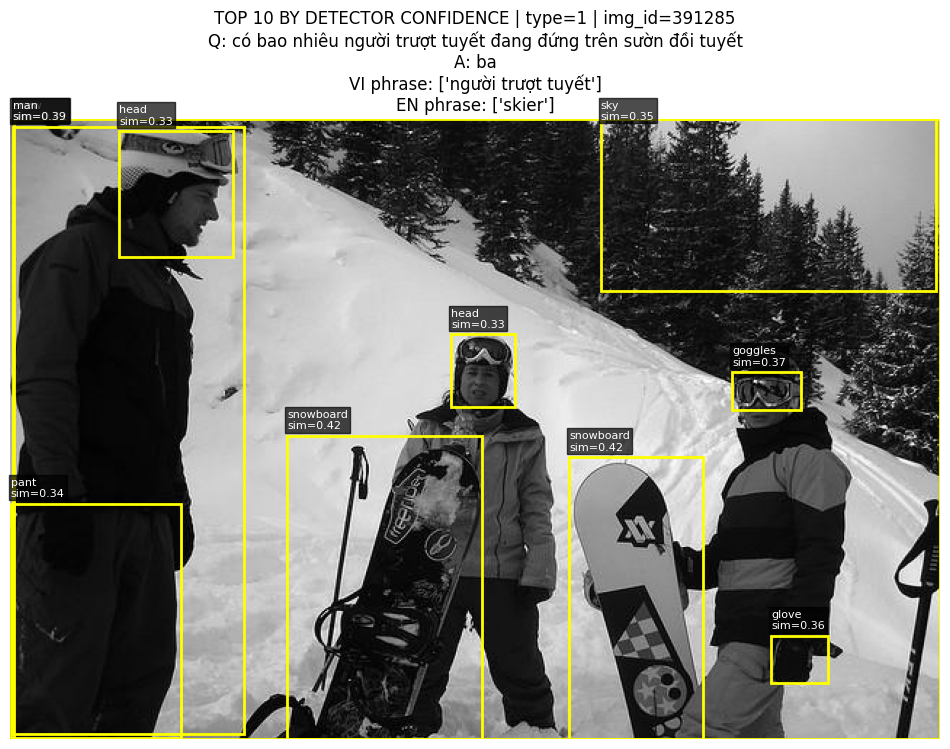

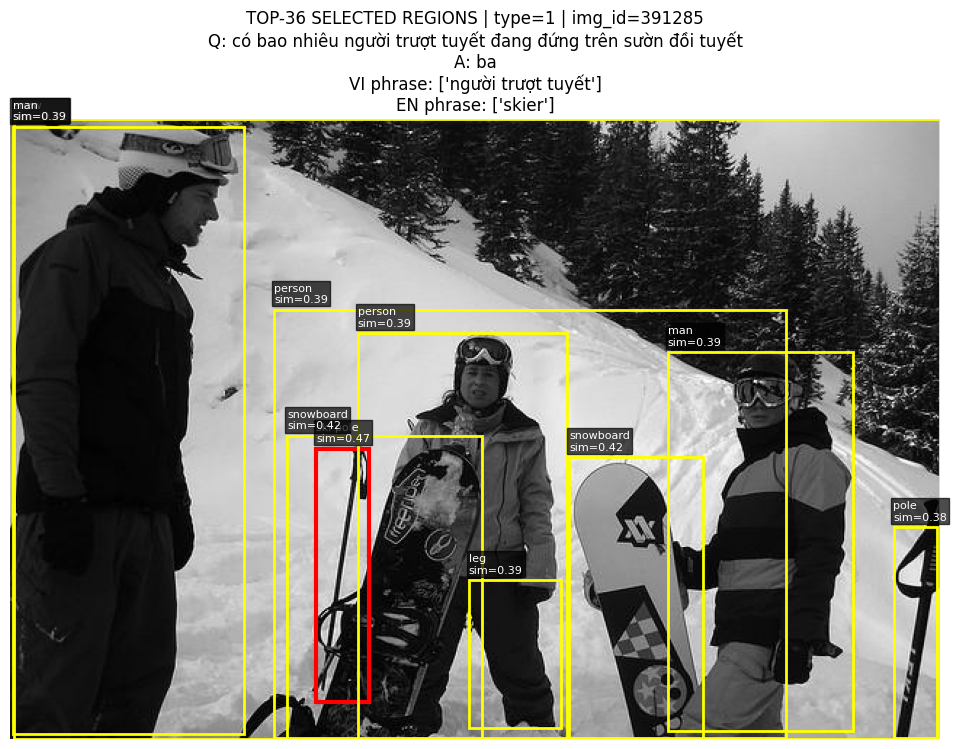

Image ID: 391285
Question type: 1
Question: có bao nhiêu người trượt tuyết đang đứng trên sườn đồi tuyết
Answer: ba
Selected VI phrase(s): ['người trượt tuyết']
Selected EN phrase(s): ['skier']
----------------------------------------------------------------------------------------------------------------------------------------------------------------
Top 10 by detector confidence:
rank= 1 | region= 0 | label=snowboard | det=0.9487 | sim=0.4182 | final=0.4182
rank= 2 | region= 1 | label=snowboard | det=0.9287 | sim=0.4182 | final=0.4182
rank= 3 | region= 2 | label=glove | det=0.8018 | sim=0.3570 | final=0.3570
rank= 4 | region= 3 | label=pant | det=0.7729 | sim=0.3388 | final=0.3388
rank= 5 | region= 4 | label=head | det=0.7686 | sim=0.3319 | final=0.3319
rank= 6 | region= 5 | label=snow | det=0.7637 | sim=0.4194 | final=0.4194
rank= 7 | region= 6 | label=man | det=0.7485 | sim=0.3898 | final=0.3898
rank= 8 | region= 7 | label=sky | det=0.7046 | sim=0.3492 | final=0.3492
rank= 9 | reg

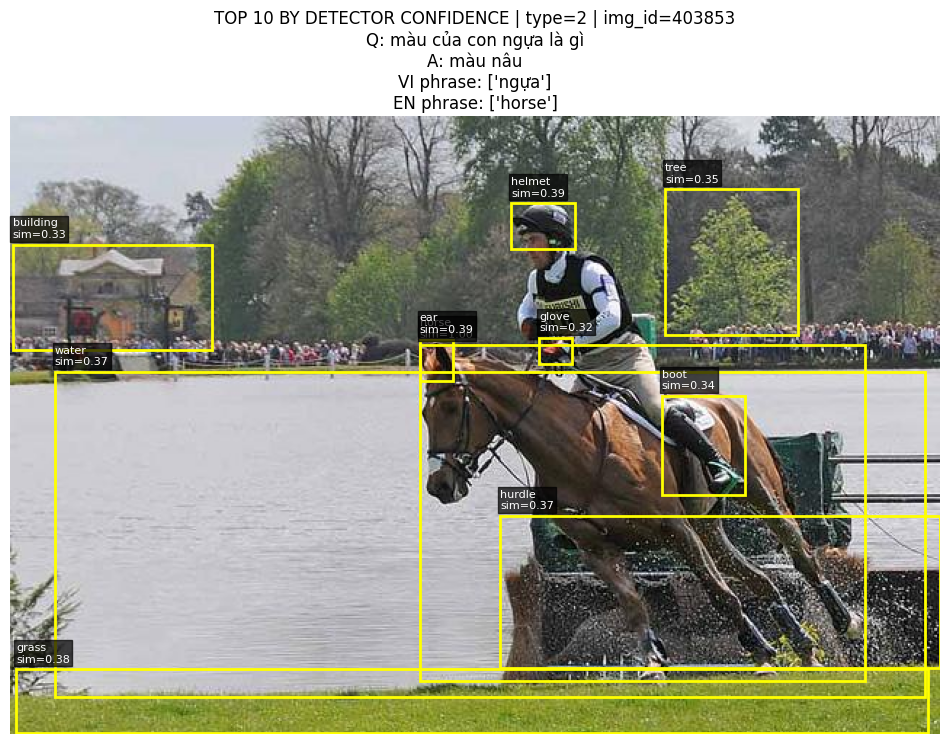

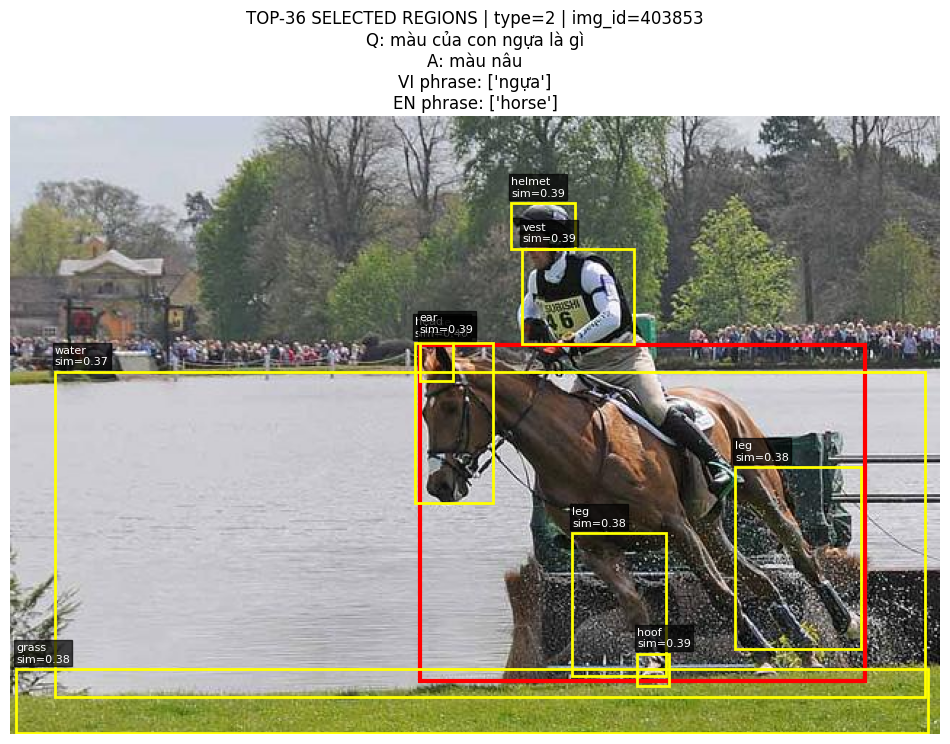

Image ID: 403853
Question type: 2
Question: màu của con ngựa là gì
Answer: màu nâu
Selected VI phrase(s): ['ngựa']
Selected EN phrase(s): ['horse']
----------------------------------------------------------------------------------------------------------------------------------------------------------------
Top 10 by detector confidence:
rank= 1 | region= 0 | label=horse | det=0.9897 | sim=1.0000 | final=1.0000
rank= 2 | region= 1 | label=helmet | det=0.9399 | sim=0.3861 | final=0.3861
rank= 3 | region= 2 | label=boot | det=0.9375 | sim=0.3371 | final=0.3371
rank= 4 | region= 3 | label=water | det=0.8662 | sim=0.3712 | final=0.3712
rank= 5 | region= 4 | label=grass | det=0.8506 | sim=0.3819 | final=0.3819
rank= 6 | region= 5 | label=tree | det=0.7915 | sim=0.3520 | final=0.3520
rank= 7 | region= 6 | label=hurdle | det=0.7744 | sim=0.3686 | final=0.3686
rank= 8 | region= 7 | label=building | det=0.7627 | sim=0.3268 | final=0.3268
rank= 9 | region= 8 | label=ear | det=0.7256 | sim=0.3879

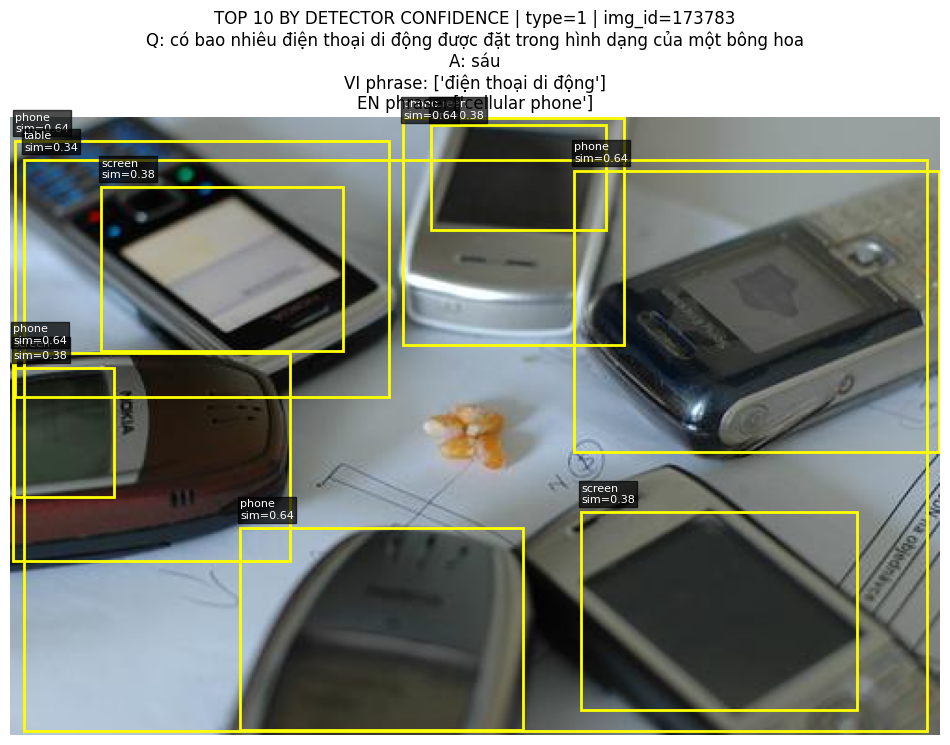

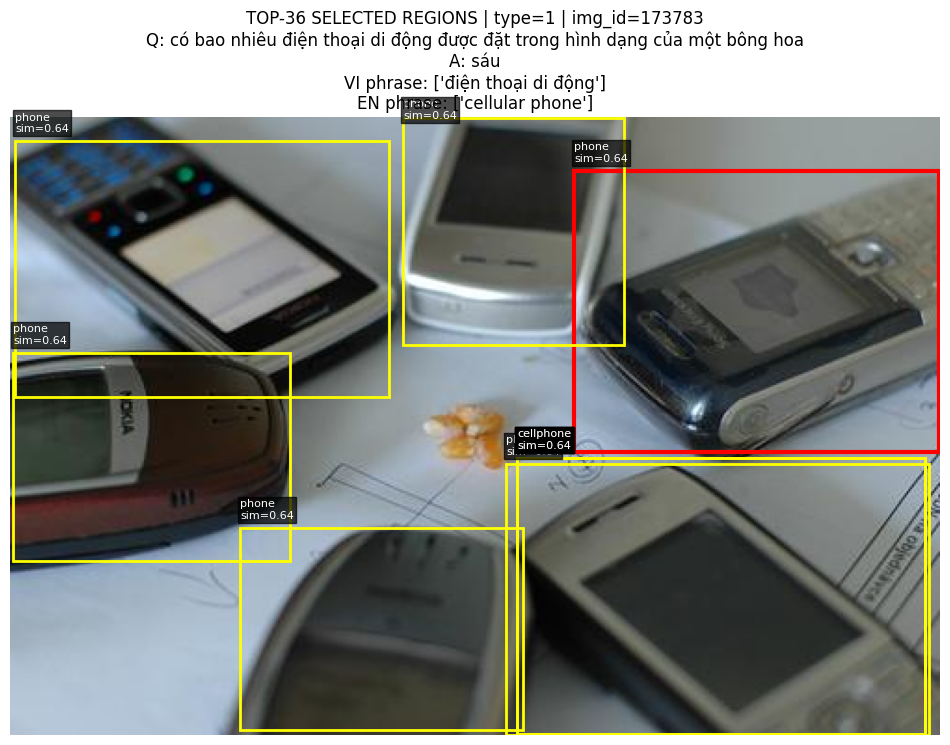

Image ID: 173783
Question type: 1
Question: có bao nhiêu điện thoại di động được đặt trong hình dạng của một bông hoa
Answer: sáu
Selected VI phrase(s): ['điện thoại di động']
Selected EN phrase(s): ['cellular phone']
----------------------------------------------------------------------------------------------------------------------------------------------------------------
Top 10 by detector confidence:
rank= 1 | region= 0 | label=screen | det=0.9653 | sim=0.3839 | final=0.3839
rank= 2 | region= 1 | label=screen | det=0.9570 | sim=0.3839 | final=0.3839
rank= 3 | region= 2 | label=phone | det=0.8838 | sim=0.6378 | final=0.6378
rank= 4 | region= 3 | label=screen | det=0.8818 | sim=0.3839 | final=0.3839
rank= 5 | region= 4 | label=screen | det=0.8164 | sim=0.3839 | final=0.3839
rank= 6 | region= 5 | label=phone | det=0.8130 | sim=0.6378 | final=0.6378
rank= 7 | region= 6 | label=phone | det=0.8125 | sim=0.6378 | final=0.6378
rank= 8 | region= 7 | label=phone | det=0.7769 | sim=0.6378 |

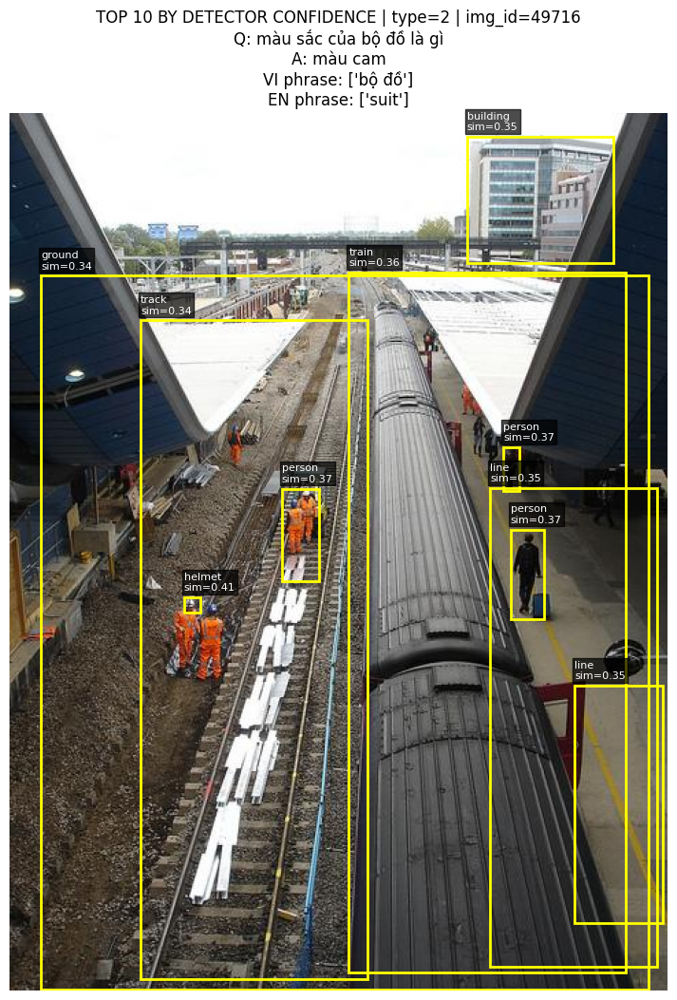

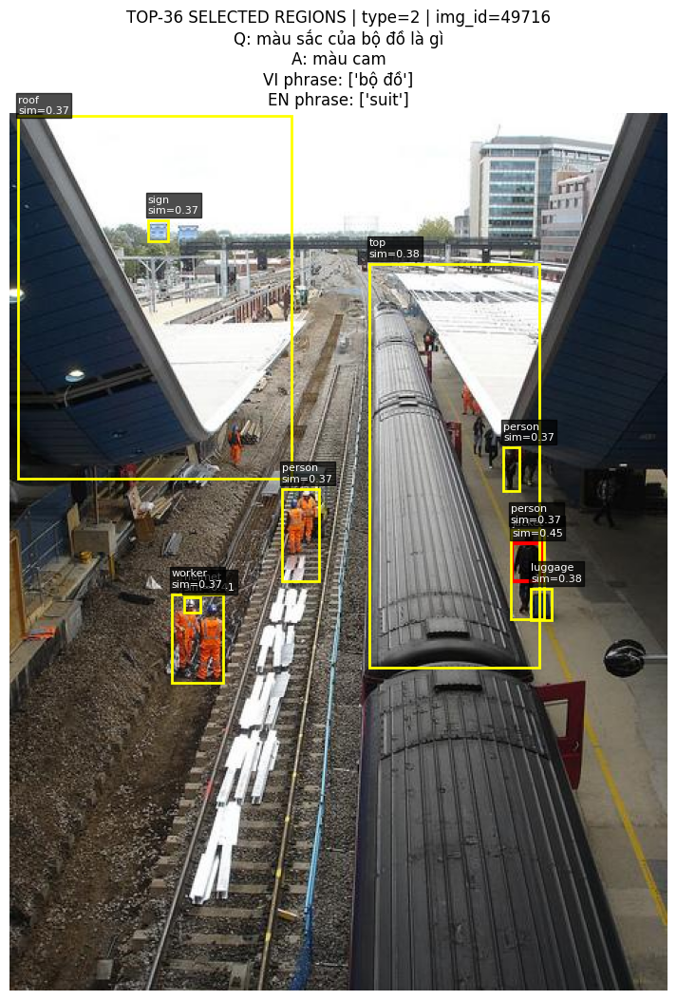

Image ID: 49716
Question type: 2
Question: màu sắc của bộ đồ là gì
Answer: màu cam
Selected VI phrase(s): ['bộ đồ']
Selected EN phrase(s): ['suit']
----------------------------------------------------------------------------------------------------------------------------------------------------------------
Top 10 by detector confidence:
rank= 1 | region= 0 | label=track | det=0.8257 | sim=0.3354 | final=0.3354
rank= 2 | region= 1 | label=line | det=0.7373 | sim=0.3508 | final=0.3508
rank= 3 | region= 2 | label=building | det=0.7329 | sim=0.3475 | final=0.3475
rank= 4 | region= 3 | label=train | det=0.7144 | sim=0.3582 | final=0.3582
rank= 5 | region= 4 | label=helmet | det=0.6768 | sim=0.4139 | final=0.4139
rank= 6 | region= 5 | label=person | det=0.6221 | sim=0.3684 | final=0.3684
rank= 7 | region= 6 | label=ground | det=0.5796 | sim=0.3396 | final=0.3396
rank= 8 | region= 7 | label=person | det=0.5737 | sim=0.3684 | final=0.3684
rank= 9 | region= 8 | label=line | det=0.5737 | sim=0.

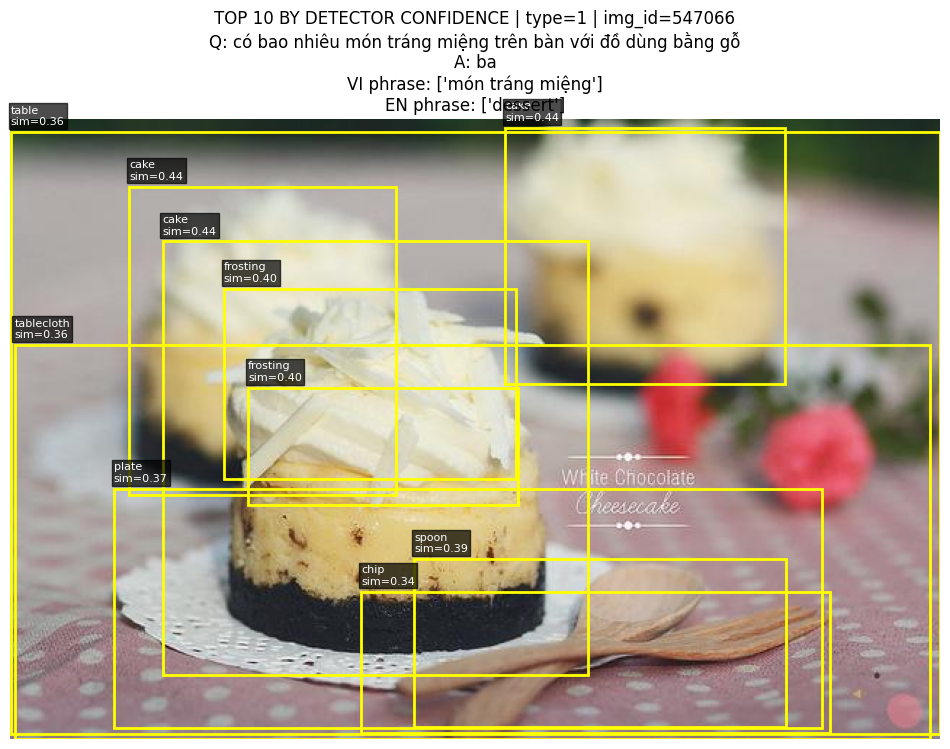

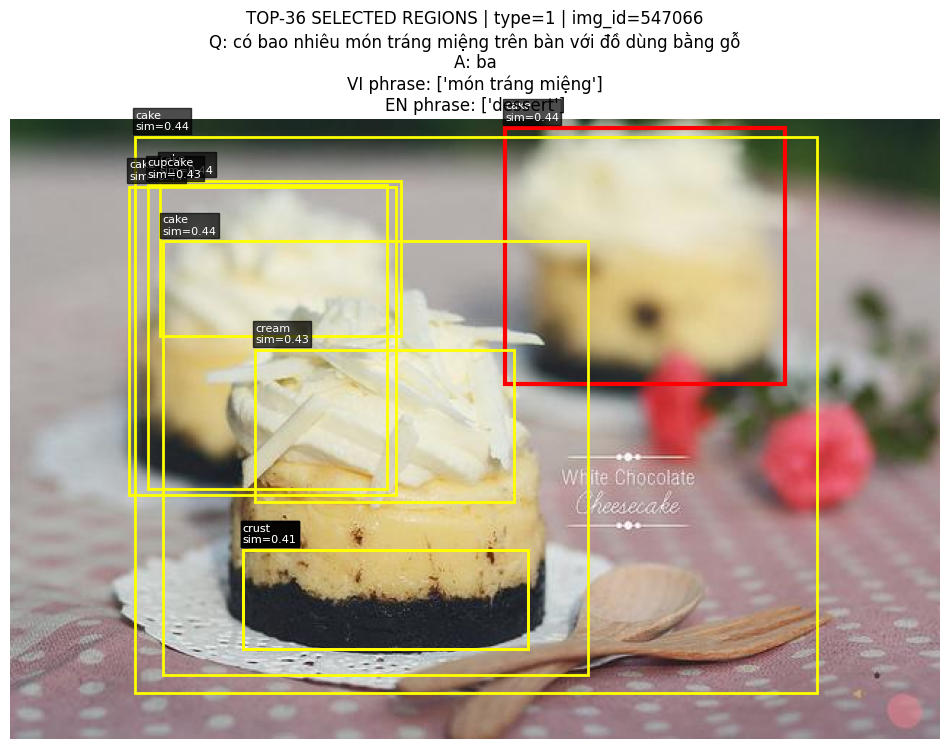

Image ID: 547066
Question type: 1
Question: có bao nhiêu món tráng miệng trên bàn với đồ dùng bằng gỗ
Answer: ba
Selected VI phrase(s): ['món tráng miệng']
Selected EN phrase(s): ['dessert']
----------------------------------------------------------------------------------------------------------------------------------------------------------------
Top 10 by detector confidence:
rank= 1 | region= 0 | label=cake | det=0.8701 | sim=0.4364 | final=0.4364
rank= 2 | region= 1 | label=spoon | det=0.7339 | sim=0.3920 | final=0.3920
rank= 3 | region= 2 | label=table | det=0.7236 | sim=0.3606 | final=0.3606
rank= 4 | region= 3 | label=cake | det=0.7183 | sim=0.4364 | final=0.4364
rank= 5 | region= 4 | label=cake | det=0.7178 | sim=0.4364 | final=0.4364
rank= 6 | region= 5 | label=chip | det=0.6108 | sim=0.3445 | final=0.3445
rank= 7 | region= 6 | label=plate | det=0.5610 | sim=0.3713 | final=0.3713
rank= 8 | region= 7 | label=frosting | det=0.5171 | sim=0.4027 | final=0.4027
rank= 9 | region= 

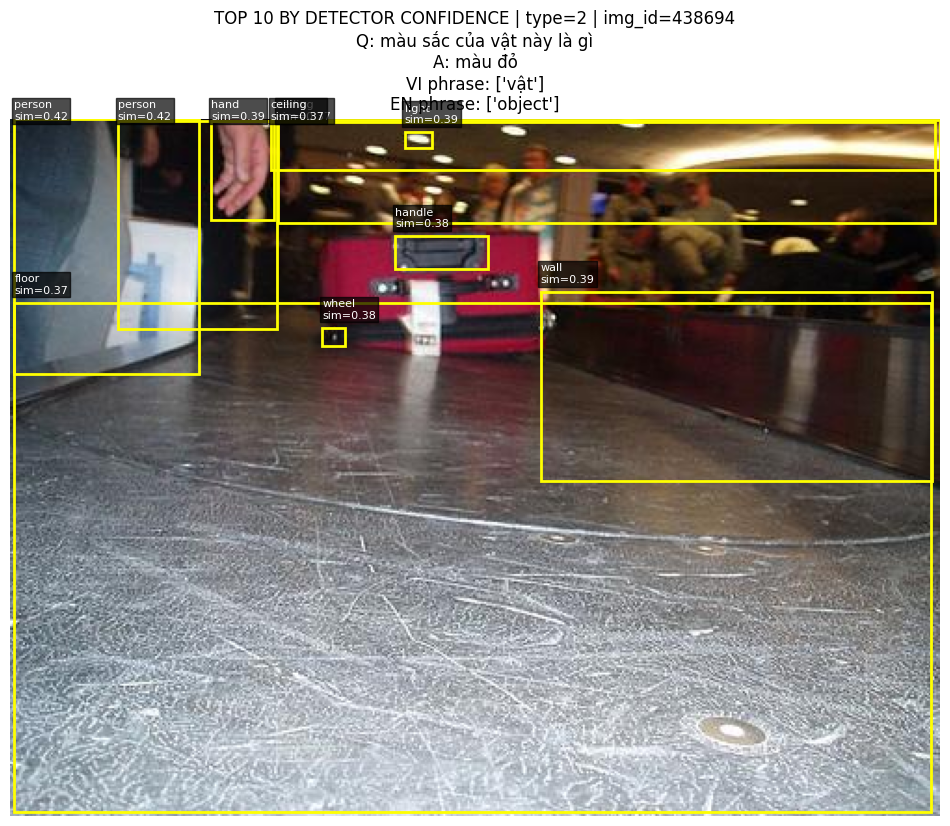

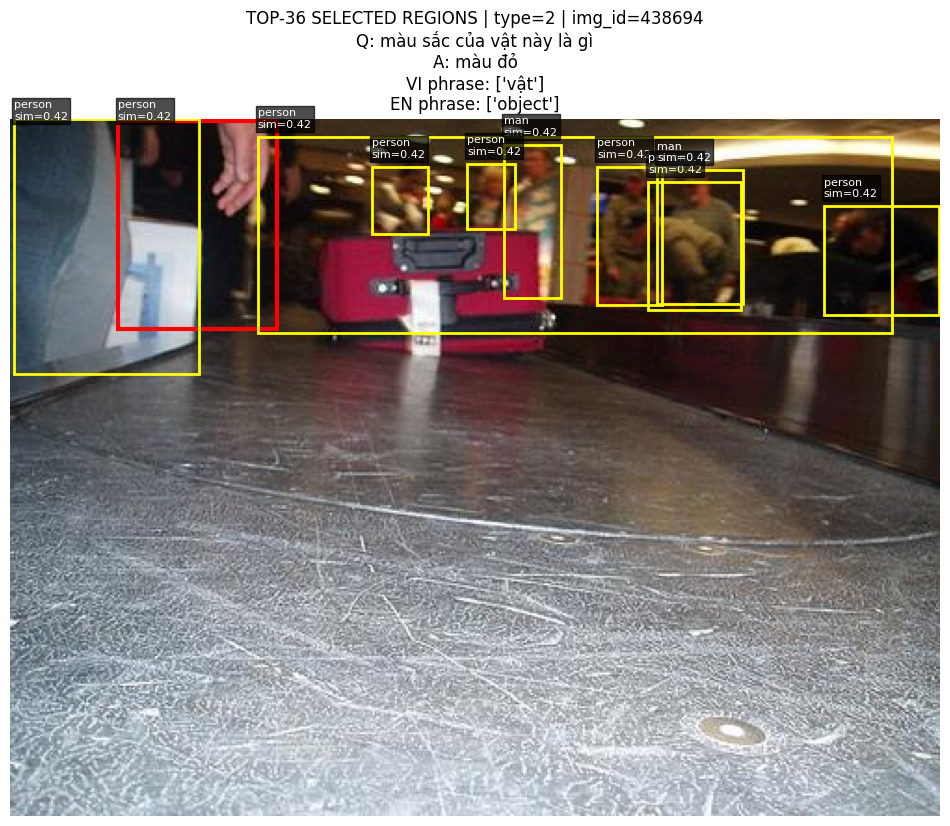

Image ID: 438694
Question type: 2
Question: màu sắc của vật này là gì
Answer: màu đỏ
Selected VI phrase(s): ['vật']
Selected EN phrase(s): ['object']
----------------------------------------------------------------------------------------------------------------------------------------------------------------
Top 10 by detector confidence:
rank= 1 | region= 0 | label=ceiling | det=0.8945 | sim=0.3744 | final=0.3744
rank= 2 | region= 1 | label=handle | det=0.8076 | sim=0.3778 | final=0.3778
rank= 3 | region= 2 | label=hand | det=0.7129 | sim=0.3872 | final=0.3872
rank= 4 | region= 3 | label=person | det=0.7114 | sim=0.4214 | final=0.4214
rank= 5 | region= 4 | label=person | det=0.6606 | sim=0.4214 | final=0.4214
rank= 6 | region= 5 | label=ceiling | det=0.6206 | sim=0.3744 | final=0.3744
rank= 7 | region= 6 | label=floor | det=0.5454 | sim=0.3705 | final=0.3705
rank= 8 | region= 7 | label=wheel | det=0.5425 | sim=0.3816 | final=0.3816
rank= 9 | region= 8 | label=wall | det=0.5371 | sim=

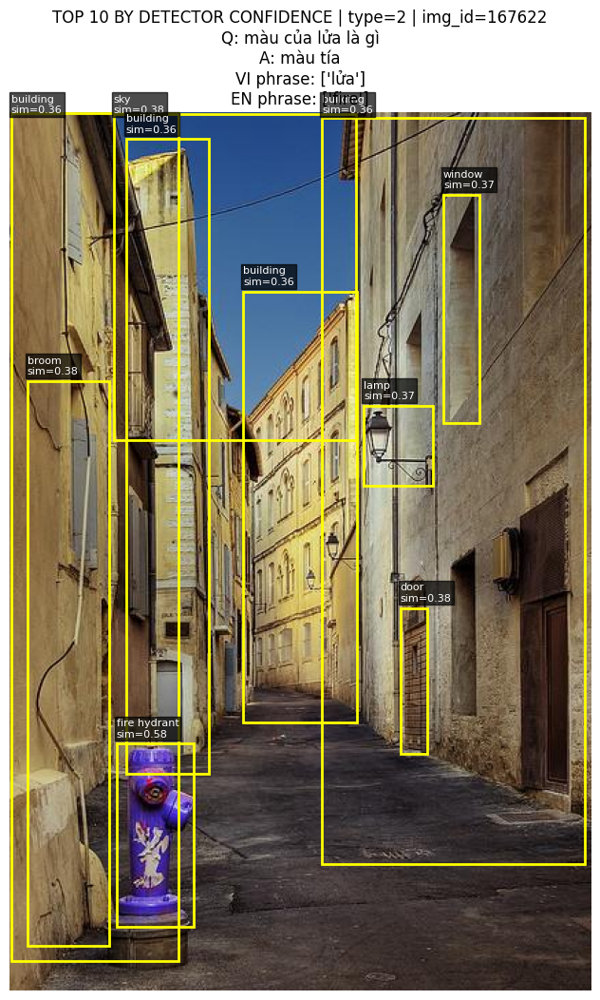

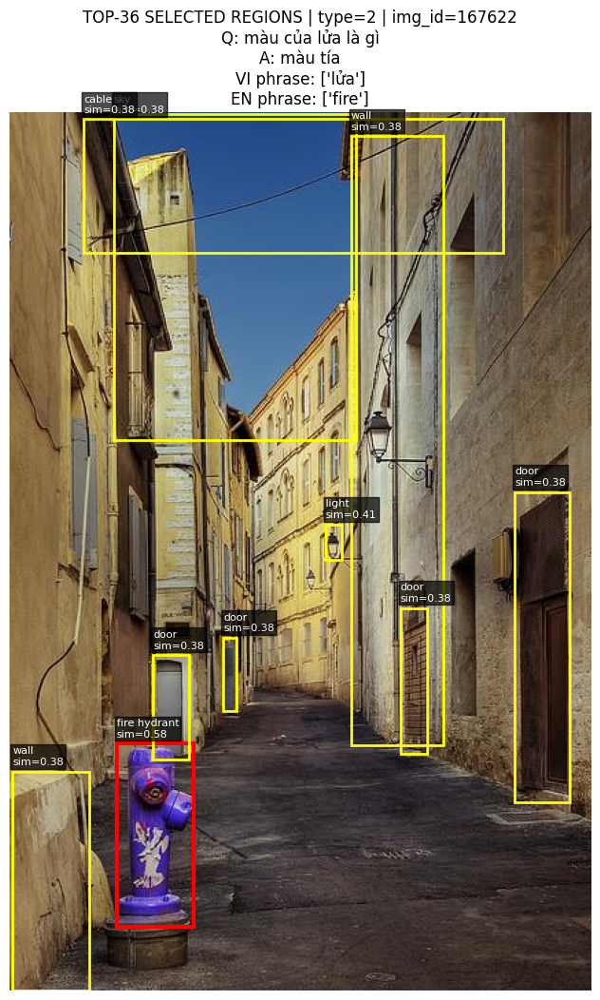

Image ID: 167622
Question type: 2
Question: màu của lửa là gì
Answer: màu tía
Selected VI phrase(s): ['lửa']
Selected EN phrase(s): ['fire']
----------------------------------------------------------------------------------------------------------------------------------------------------------------
Top 10 by detector confidence:
rank= 1 | region= 0 | label=sky | det=0.9692 | sim=0.3774 | final=0.3774
rank= 2 | region= 1 | label=building | det=0.9395 | sim=0.3607 | final=0.3607
rank= 3 | region= 2 | label=building | det=0.8242 | sim=0.3607 | final=0.3607
rank= 4 | region= 3 | label=fire hydrant | det=0.8242 | sim=0.5810 | final=0.5810
rank= 5 | region= 4 | label=building | det=0.7227 | sim=0.3607 | final=0.3607
rank= 6 | region= 5 | label=building | det=0.7139 | sim=0.3607 | final=0.3607
rank= 7 | region= 6 | label=door | det=0.6958 | sim=0.3811 | final=0.3811
rank= 8 | region= 7 | label=lamp | det=0.6699 | sim=0.3730 | final=0.3730
rank= 9 | region= 8 | label=broom | det=0.6597 | sim

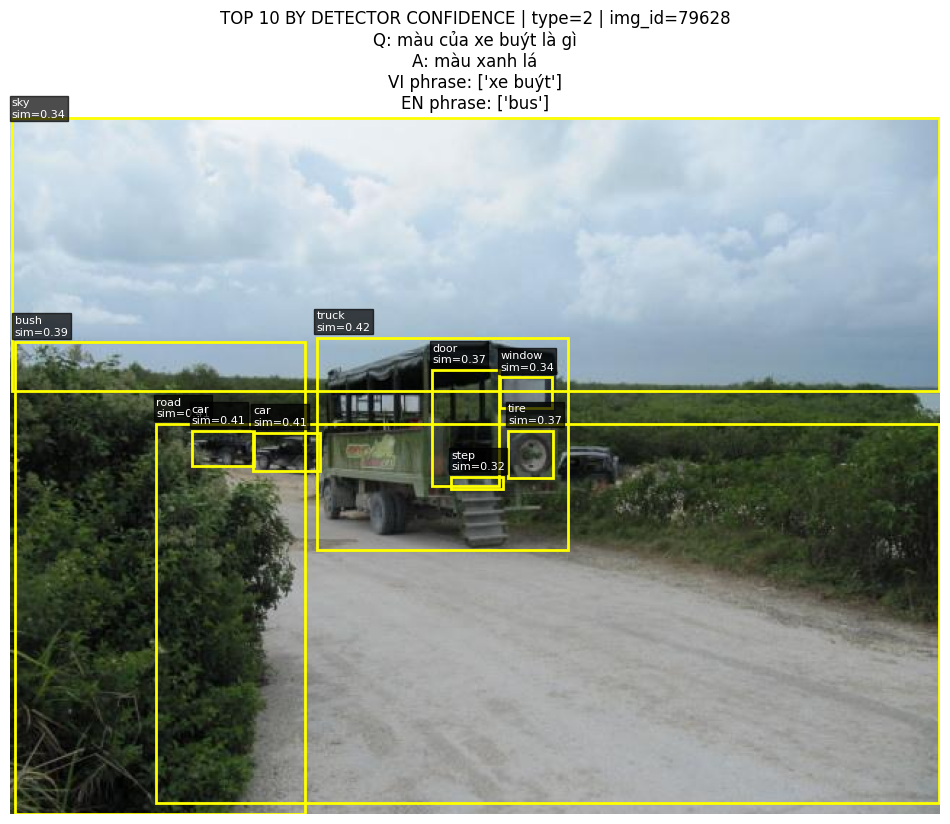

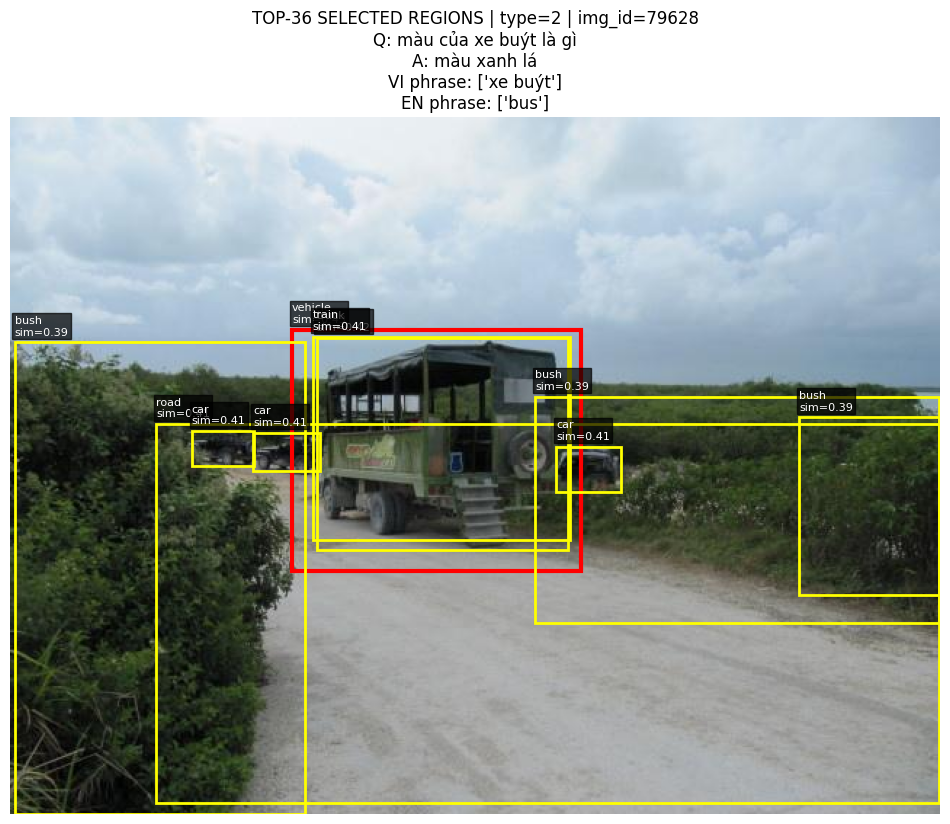

Image ID: 79628
Question type: 2
Question: màu của xe buýt là gì
Answer: màu xanh lá
Selected VI phrase(s): ['xe buýt']
Selected EN phrase(s): ['bus']
----------------------------------------------------------------------------------------------------------------------------------------------------------------
Top 10 by detector confidence:
rank= 1 | region= 0 | label=tire | det=0.8770 | sim=0.3667 | final=0.3667
rank= 2 | region= 1 | label=window | det=0.8433 | sim=0.3412 | final=0.3412
rank= 3 | region= 2 | label=road | det=0.8228 | sim=0.4114 | final=0.4114
rank= 4 | region= 3 | label=sky | det=0.7295 | sim=0.3392 | final=0.3392
rank= 5 | region= 4 | label=truck | det=0.7256 | sim=0.4155 | final=0.4155
rank= 6 | region= 5 | label=step | det=0.6099 | sim=0.3151 | final=0.3151
rank= 7 | region= 6 | label=car | det=0.5840 | sim=0.4113 | final=0.4113
rank= 8 | region= 7 | label=car | det=0.5728 | sim=0.4113 | final=0.4113
rank= 9 | region= 8 | label=bush | det=0.5728 | sim=0.3896 | fina

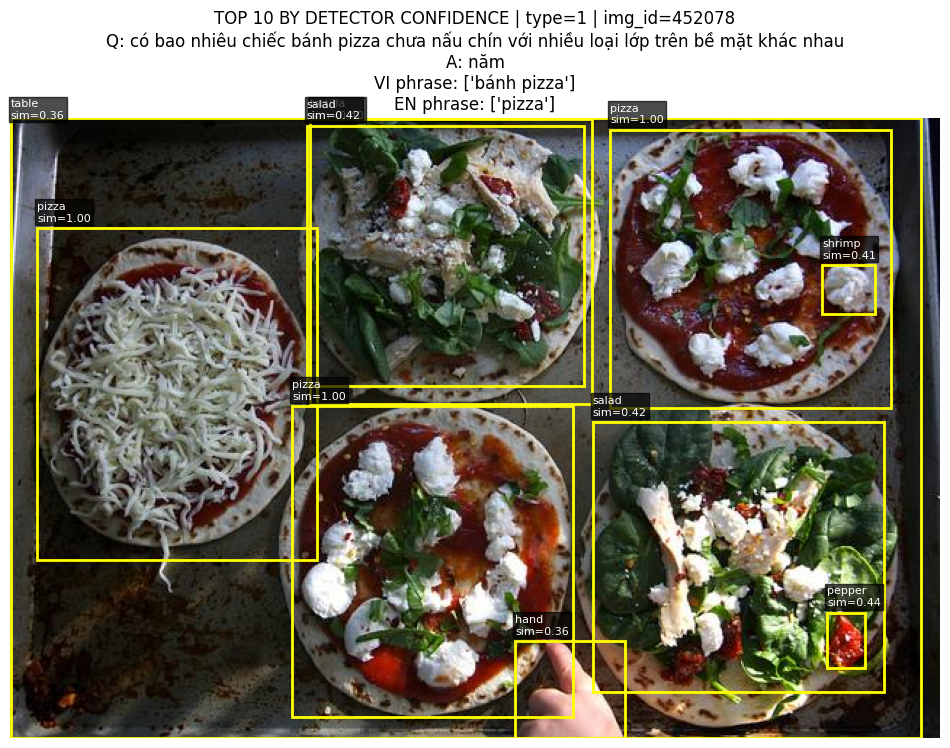

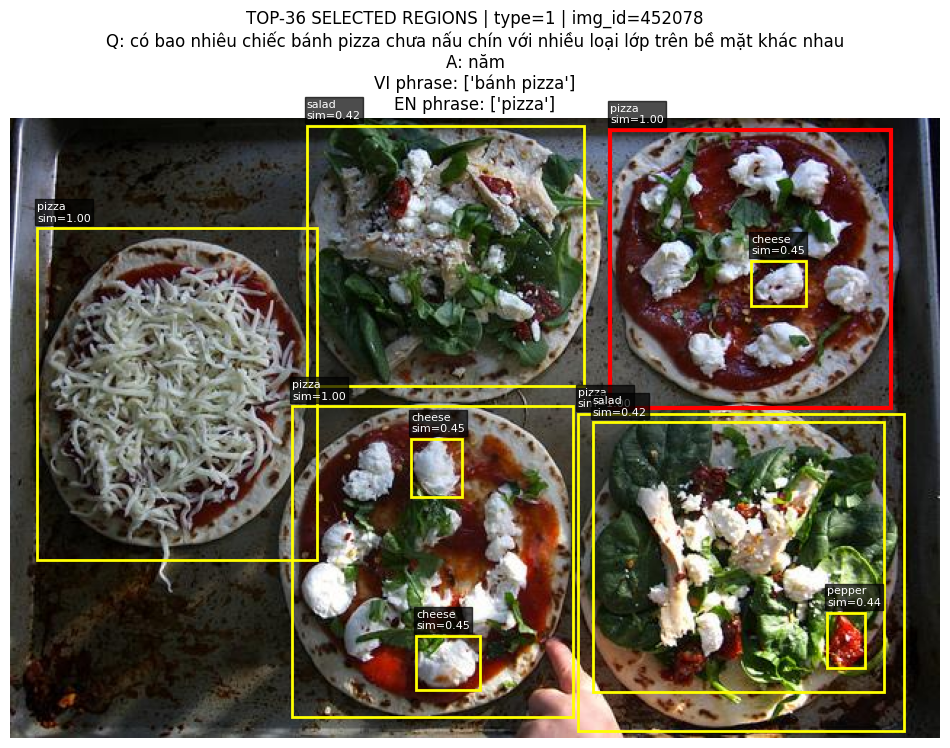

Image ID: 452078
Question type: 1
Question: có bao nhiêu chiếc bánh pizza chưa nấu chín với nhiều loại lớp trên bề mặt khác nhau
Answer: năm
Selected VI phrase(s): ['bánh pizza']
Selected EN phrase(s): ['pizza']
----------------------------------------------------------------------------------------------------------------------------------------------------------------
Top 10 by detector confidence:
rank= 1 | region= 0 | label=tortilla | det=0.9814 | sim=0.3951 | final=0.3951
rank= 2 | region= 1 | label=pizza | det=0.9780 | sim=1.0000 | final=1.0000
rank= 3 | region= 2 | label=pizza | det=0.9263 | sim=1.0000 | final=1.0000
rank= 4 | region= 3 | label=shrimp | det=0.9141 | sim=0.4081 | final=0.4081
rank= 5 | region= 4 | label=salad | det=0.8691 | sim=0.4234 | final=0.4234
rank= 6 | region= 5 | label=pizza | det=0.8159 | sim=1.0000 | final=1.0000
rank= 7 | region= 6 | label=pepper | det=0.6421 | sim=0.4360 | final=0.4360
rank= 8 | region= 7 | label=hand | det=0.5449 | sim=0.3592 | final

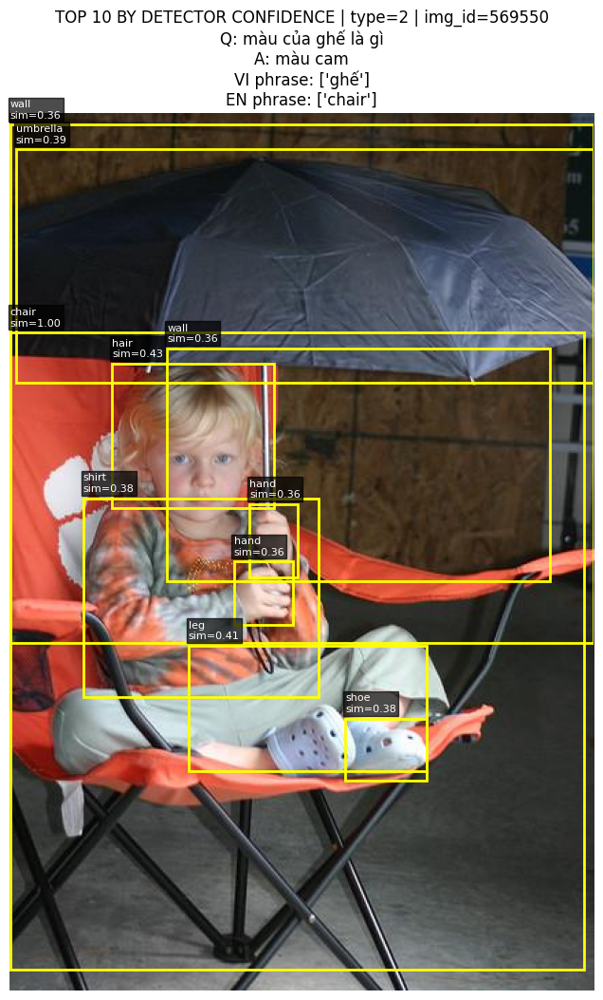

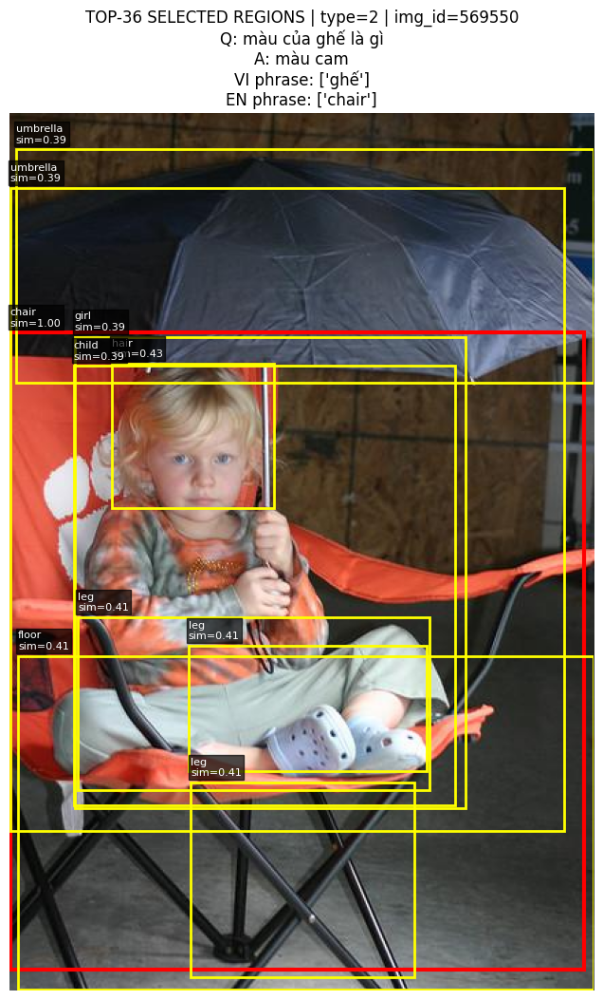

Image ID: 569550
Question type: 2
Question: màu của ghế là gì
Answer: màu cam
Selected VI phrase(s): ['ghế']
Selected EN phrase(s): ['chair']
----------------------------------------------------------------------------------------------------------------------------------------------------------------
Top 10 by detector confidence:
rank= 1 | region= 0 | label=chair | det=0.8633 | sim=1.0000 | final=1.0000
rank= 2 | region= 1 | label=wall | det=0.8105 | sim=0.3581 | final=0.3581
rank= 3 | region= 2 | label=umbrella | det=0.8066 | sim=0.3915 | final=0.3915
rank= 4 | region= 3 | label=shirt | det=0.7383 | sim=0.3804 | final=0.3804
rank= 5 | region= 4 | label=leg | det=0.7368 | sim=0.4149 | final=0.4149
rank= 6 | region= 5 | label=shoe | det=0.7217 | sim=0.3772 | final=0.3772
rank= 7 | region= 6 | label=hair | det=0.6729 | sim=0.4277 | final=0.4277
rank= 8 | region= 7 | label=wall | det=0.6543 | sim=0.3581 | final=0.3581
rank= 9 | region= 8 | label=hand | det=0.6470 | sim=0.3644 | final=0.

In [23]:
visualize_css_scoring(df_test, num_samples=10, allowed_types={1, 2}, seed=42)